## Problem Understanding

**Context**

Perkembangan industri music streaming digital telah menghasilkan ketersediaan jutaan lagu dengan beragam karakteristik audio dan genre. Kondisi ini menciptakan tantangan information overload, di mana pengguna kesulitan menemukan konten musik yang relevan dengan preferensi pribadi mereka secara efisien. Sistem rekomendasi menjadi komponen krusial dalam meningkatkan pengalaman pengguna (user experience) dengan menyediakan konten yang sesuai, personal, dan berkualitas.

Pendekatan rekomendasi tradisional yang hanya mengandalkan popularitas atau histori interaksi pengguna memiliki keterbatasan, terutama dalam menghadapi masalah cold-start (pengguna baru atau lagu baru tanpa histori interaksi). Oleh karena itu, diperlukan pendekatan berbasis data audio (audio feature-driven approach) yang memanfaatkan karakteristik intrinsik lagu seperti danceability, energy, valence, tempo, acousticness, dan atribut musikal lainnya. Pendekatan ini memungkinkan pengembangan sistem rekomendasi yang objektif, skalabel, dan independen dari perilaku pengguna.

**Problem Statement**

Meskipun dataset musik mengandung informasi audio features yang kaya dan representatif terhadap karakteristik musikal lagu, belum terdapat sistem terintegrasi yang mampu memanfaatkan fitur-fitur tersebut untuk membangun model rekomendasi lagu berbasis kemiripan konten (content-based similarity). Ketiadaan sistem ini mengakibatkan proses rekomendasi lagu menjadi kurang personal, kurang relevan, dan tidak optimal dalam mendukung eksplorasi musik oleh pengguna. Hal ini membatasi kualitas pengalaman pengguna serta efektivitas platform dalam meningkatkan engagement, retensi, dan kepuasan pengguna.

**Project Goal**

Proyek ini bertujuan untuk membangun sebuah sistem rekomendasi lagu berbasis konten (content-based recommendation system) yang memanfaatkan karakteristik audio dan metadata lagu sebagai dasar utama dalam proses rekomendasi. Sistem ini dikembangkan melalui tahapan analisis data eksploratif (Exploratory Data Analysis/EDA) untuk memahami struktur, distribusi, dan pola dalam data, dilanjutkan dengan proses representasi fitur lagu dalam bentuk vektor numerik yang terstandarisasi serta penerapan metode pengukuran kemiripan (similarity measurement) untuk mengidentifikasi kedekatan karakteristik antar lagu. Hasil akhir dari proyek ini adalah sebuah fungsi sistem rekomendasi otomatis yang mampu menerima input teks dan menghasilkan daftar rekomendasi lagu yang relevan secara musikal, sehingga dapat mendukung personalisasi konten, meningkatkan pengalaman pengguna (user experience), serta mengoptimalkan engagement dan retensi pengguna dalam platform music streaming berbasis pendekatan data-driven.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('song_recomendation_A.csv',sep=',')
df.head()

,Track URI,Track Name,Artist Name(s),Album Name,Album Release Date,Popularity,Artist Genres,Danceability,Energy,Key,Loudness,Mode,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Time Signature
0,spotify:track:38tpcZDofjtDNunMm5w1EU,If I Could Change Your Mind,HAIM,Days Are Gone (Deluxe Edition),2013-01-01,53,"indietronica,metropopolis",0.671,0.852,2.0,-5.557,0.0,0.0425,0.01840,0.000099,0.0841,0.737,125.043,4.0
1,spotify:track:60lJebAiPbIrnLeGev6kHX,If I Ain't Got You,Alicia Keys,The Diary Of Alicia Keys,2003,0,"neo soul,pop,r&b",0.589,0.449,7.0,-9.153,1.0,0.1050,0.60700,0.000022,0.1000,0.159,118.351,3.0
2,spotify:track:1dbt3sOwRmUOLfQZSpSz9O,Truly,Lionel Richie,Lionel Richie (Expanded Edition),1982,0,soft rock,0.366,0.238,1.0,-13.853,1.0,0.0381,0.64600,0.000010,0.0876,0.131,68.362,4.0
3,spotify:track:50PeqUz1BjMw9ayNTk5O4d,I've Been Thinking About You,Londonbeat,Best! The Singles 16 Tracks,1995-11-20,69,"eurodance,hip house",0.678,0.659,11.0,-12.695,0.0,0.0396,0.02360,0.001920,0.0744,0.899,113.542,4.0
4,spotify:track:111P8I22TrLyxQm7Jcwdoy,Kung Fu Fighting,"Bus Stop, Carl Douglas",The Soul of the Kung Fu Fighter,1972-02-13,0,NaN,0.737,0.855,11.0,-10.319,0.0,0.0646,0.00475,0.000017,0.1630,0.583,116.023,4.0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Track URI           5000 non-null   object 
 1   Track Name          4999 non-null   object 
 2   Artist Name(s)      4999 non-null   object 
 3   Album Name          4999 non-null   object 
 4   Album Release Date  5000 non-null   object 
 5   Popularity          5000 non-null   int64  
 6   Artist Genres       4705 non-null   object 
 7   Danceability        5000 non-null   float64
 8   Energy              5000 non-null   float64
 9   Key                 5000 non-null   float64
 10  Loudness            5000 non-null   float64
 11  Mode                5000 non-null   float64
 12  Speechiness         5000 non-null   float64
 13  Acousticness        4850 non-null   float64
 14  Instrumentalness    5000 non-null   float64
 15  Liveness            5000 non-null   float64
 16  Valenc

In [4]:
# Numerical statistical summary
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Popularity,5000.0,37.186600,29.416282,0.000000,0.000000,41.000000,63.000000,95.000
Danceability,5000.0,0.607829,0.146753,0.099400,0.513000,0.619000,0.712000,0.988
Energy,5000.0,0.683985,0.190948,0.020500,0.564000,0.710000,0.836000,0.994
Key,5000.0,5.189800,3.590314,0.000000,2.000000,5.000000,8.000000,11.000
Loudness,5000.0,-7.287859,3.321153,-23.242000,-9.080000,-6.492000,-4.905000,2.769
Mode,5000.0,0.702800,0.457071,0.000000,0.000000,1.000000,1.000000,1.000
Speechiness,5000.0,0.064971,0.060141,0.021800,0.033300,0.043100,0.068300,0.519
Acousticness,4850.0,0.208017,0.248286,0.000003,0.018400,0.098150,0.312000,0.991
Instrumentalness,5000.0,0.031162,0.128110,0.000000,0.000000,0.000005,0.000603,0.985
Liveness,5000.0,0.186385,0.150530,0.012000,0.089175,0.127000,0.247250,0.989


In [5]:
#Categorical statistical summary
df.describe(include=object)

,Track URI,Track Name,Artist Name(s),Album Name,Album Release Date,Artist Genres
count,5000,4999,4999,4999,5000,4705
unique,4988,4510,2653,3886,2227,1902
top,spotify:track:7hQJA50XrCWABAu5v6QZ4i,One,Elvis Presley,Greatest Hits,2011-01-01,"dance pop,pop"
freq,3,6,27,51,70,121


**Dataset terdiri dari 5.000 lagu dengan 19 variabel yang mencakup metadata dan audio features. Terdapat beberapa missing values pada kolom tertentu sehingga diperlukan tahap imputasi data sebelum proses pemodelan. Distribusi popularitas menunjukkan bahwa dataset tidak didominasi oleh lagu viral, melainkan merepresentasikan katalog musik secara umum. Secara karakteristik musikal, mayoritas lagu memiliki danceability dan energy yang tinggi, valence yang cenderung positif, serta tempo sedang hingga cepat (±120 BPM), dengan struktur musik yang didominasi oleh mode mayor dan time signature 4/4. Dataset juga memiliki keragaman genre, artis, dan album yang tinggi, sehingga sangat layak digunakan untuk membangun sistem rekomendasi lagu berbasis konten (content-based recommendation system) melalui pendekatan similarity modeling.**

**Check Missing Value**

In [6]:
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100

missing_df = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": missing_percent
}).sort_values(by="Missing Percentage", ascending=False)

missing_df

,Missing Count,Missing Percentage
Artist Genres,295,5.90
Tempo,250,5.00
Acousticness,150,3.00
Track Name,1,0.02
Artist Name(s),1,0.02
Album Name,1,0.02
Track URI,0,0.00
Danceability,0,0.00
Energy,0,0.00
Album Release Date,0,0.00


**Hasil pengecekan missing values menunjukkan bahwa sebagian besar variabel berada dalam kondisi lengkap, dengan hanya beberapa kolom yang memiliki data hilang, yaitu Artist Genres (5.9%), Tempo (5.0%), Acousticness (3.0%), serta missing minor pada Track Name, Artist Name(s), dan Album Name (0.02%). Secara proporsional, tingkat missing values relatif rendah (<6%), sehingga dataset tetap memiliki kualitas yang baik dan layak digunakan untuk pemodelan. Namun, karena kolom yang memiliki missing values mencakup fitur penting untuk sistem rekomendasi (genre dan audio features), maka diperlukan proses imputasi data agar tidak mengganggu representasi fitur, perhitungan similarity, dan performa sistem rekomendasi berbasis konten.**

**Check Duplicate Data**

In [7]:
df.duplicated().sum()

np.int64(9)

In [8]:
# drop data duplicate
df = df.drop_duplicates().reset_index(drop=True)

In [9]:
df.duplicated().sum()

np.int64(0)

**Check Inconsistent Data**

In [10]:
for col in df.columns:
    print(f"Unique values in column '{col}':")
    print(df[col].unique())
    print("\n")

Unique values in column 'Track URI':
['spotify:track:38tpcZDofjtDNunMm5w1EU'
 'spotify:track:60lJebAiPbIrnLeGev6kHX'
 'spotify:track:1dbt3sOwRmUOLfQZSpSz9O' ...
 'spotify:track:0TwxA1UTqCXyihWqu6PMWh'
 'spotify:track:0A4PZuepTcIQVvA5m7R0M1'
 'spotify:track:1oH5Mg9dyAj15lWUmXvmFW']


Unique values in column 'Track Name':
['If I Could Change Your Mind' "If I Ain't Got You" 'Truly' ...
 'Dreaming My Dreams with You' "Don't You (Forget About Me) - Remastered"
 'Cross Me (feat. Chance the Rapper & PnB Rock)']


Unique values in column 'Artist Name(s)':
['HAIM' 'Alicia Keys' 'Lionel Richie' ... 'Colleen Hewett' 'Simple Minds'
 'Ed Sheeran, Chance the Rapper, PnB Rock']


Unique values in column 'Album Name':
['Days Are Gone (Deluxe Edition)' 'The Diary Of Alicia Keys'
 'Lionel Richie (Expanded Edition)' ... 'Lost on You' 'Colleen'
 'Celebrate (Greatest Hits)']


Unique values in column 'Album Release Date':
['2013-01-01' '2003' '1982' ... '2012-06-01' '2008-01-25' '2013-03-25']


Unique valu

**Handling Missing Value and Inconsistent Data**

check satu persatu variabel

**Track Uri**

In [11]:
df['Track URI'].describe()

count                                     4991
unique                                    4988
top       spotify:track:3yrSvpt2l1xhsV9Em88Pul
freq                                         2
Name: Track URI, dtype: object

In [12]:
df['Track URI'].value_counts()

Track URI
spotify:track:3yrSvpt2l1xhsV9Em88Pul    2
spotify:track:6kooDsorCpWVMGc994XjWN    2
spotify:track:7hQJA50XrCWABAu5v6QZ4i    2
spotify:track:4WGTwyHPMvB3HWiEO9R0wb    1
spotify:track:2oTDOIAdsxPTE7yAp4YOcv    1
                                       ..
spotify:track:2LIh4uzqq9cXMPzzmcToHl    1
spotify:track:3JhwxN5fPtpWh8O4qCBjYO    1
spotify:track:0TwxA1UTqCXyihWqu6PMWh    1
spotify:track:0A4PZuepTcIQVvA5m7R0M1    1
spotify:track:4xAJSIcCHcOCli5m325X2H    1
Name: count, Length: 4988, dtype: int64

In [13]:
df['Track URI'].isna().sum()

np.int64(0)

**jumlah entri 4.991 data dengan 4.988 nilai unik, menunjukkan bahwa mayoritas lagu kini memiliki identifier yang unik. Tidak ditemukan missing values pada kolom Track URI, sehingga kolom ini bersih secara kelengkapan data. Sisa duplikasi kecil yang muncul merepresentasikan kasus minor yang tidak signifikan terhadap pemodelan dan tidak memengaruhi sistem rekomendasi secara struktural. Track URI tetap diperlakukan sebagai identifier, bukan sebagai fitur pemodelan, dan digunakan untuk keperluan identifikasi serta output rekomendasi lagu.**

**Track Name**

In [14]:
df['Track Name'].describe()

count     4990
unique    4510
top        One
freq         6
Name: Track Name, dtype: object

In [15]:
df['Track Name'].value_counts()

Track Name
One                                              6
Last Night                                       6
How Deep Is Your Love                            5
Stay                                             5
Higher                                           5
                                                ..
If I Could Change Your Mind                      1
Cross Me (feat. Chance the Rapper & PnB Rock)    1
In My Pocket                                     1
Cathy's Clown                                    1
Whatever It Takes                                1
Name: count, Length: 4510, dtype: int64

In [16]:
df['Track Name'].isna().sum()

np.int64(1)

**Kolom Track Name memiliki 4.990 data dengan 4.510 nilai unik, yang menunjukkan adanya pengulangan judul lagu dalam dataset. Beberapa judul seperti “Last Night” dan “One” muncul lebih dari satu kali, yang secara semantik wajar karena judul lagu yang sama dapat dimiliki oleh artist berbeda atau merupakan versi lagu yang berbeda (cover, remastered, live version, atau re-release). Terdapat 1 missing value pada kolom ini, sehingga diperlukan imputasi sederhana (misalnya pengisian dengan label "Unknown"). Track Name tidak digunakan sebagai fitur pemodelan, namun berperan penting sebagai input text-based query dan sebagai informasi output dalam sistem rekomendasi lagu.**

In [17]:
# isi dengan label unkown karena ini merupakan data identitas
df['Track Name'] = df['Track Name'].fillna('Unknown')

In [18]:
df['Track Name'].isna().sum()

np.int64(0)

**Artist Name**

In [19]:
df['Artist Name(s)'].describe()

count              4990
unique             2653
top       Elvis Presley
freq                 27
Name: Artist Name(s), dtype: object

In [20]:
df['Artist Name(s)'].value_counts()

Artist Name(s)
Elvis Presley                                                                  27
P!nk                                                                           25
Taylor Swift                                                                   22
Ed Sheeran                                                                     21
The Beatles                                                                    19
                                                                               ..
George Benson                                                                   1
Gloria Estefan, Miami Sound Machine                                             1
GABRIELLE                                                                       1
Clean Bandit, Topic, Wes Nelson                                                 1
Macklemore & Ryan Lewis, Macklemore, Ryan Lewis, Idris Elba, Anderson .Paak     1
Name: count, Length: 2653, dtype: int64

In [21]:
df['Artist Name(s)'].isna().sum()

np.int64(1)

**Kolom Artist Name(s) memiliki 4.990 data dengan 2.653 nilai unik, menunjukkan tingkat keragaman artis yang tinggi dalam dataset. Beberapa artis populer seperti Elvis Presley, P!nk, Taylor Swift, Ed Sheeran, dan The Beatles muncul lebih dari satu kali, yang merepresentasikan keberadaan beberapa lagu dari artis yang sama. Terdapat 1 missing value pada kolom ini, sehingga diperlukan penanganan sederhana (pelabelan "Unknown" atau penghapusan baris). Kolom ini tidak digunakan sebagai fitur dalam similarity modeling, namun berperan penting sebagai informasi kontekstual, input text-based query, serta komponen utama dalam interpretasi dan penyajian hasil rekomendasi lagu.**

In [22]:
# Impute dengan unkown juga karena ini data identitas
df['Artist Name(s)'] = df['Artist Name(s)'].fillna('Unknown')

# Cek ulang
df['Artist Name(s)'].isna().sum()

np.int64(0)

**Album Name**

In [23]:
df['Album Name'].describe()

count              4990
unique             3886
top       Greatest Hits
freq                 51
Name: Album Name, dtype: object

In [24]:
df['Album Name'].value_counts()

Album Name
Greatest Hits                        51
The Very Best Of                     12
The Definitive Collection            12
Celebration (double disc version)    10
Anthology                            10
                                     ..
R&B Classics of the 60s               1
The Story                             1
House Of Pain                         1
No Excuses                            1
The Very Best of Todd Rundgren        1
Name: count, Length: 3886, dtype: int64

In [25]:
df['Album Name'].isna().sum()

np.int64(1)

**Kolom Album Name memiliki 4.990 data dengan 3.886 nilai unik, menunjukkan variasi album yang tinggi dalam dataset. Album seperti “Greatest Hits” muncul paling sering, yang secara semantik wajar karena banyak artis memiliki album kompilasi dengan nama serupa. Terdapat 1 missing value pada kolom ini, sehingga dilakukan imputasi menggunakan pelabelan "Unknown". Kolom ini tidak digunakan sebagai fitur dalam pemodelan similarity, namun tetap dipertahankan sebagai metadata kontekstual untuk keperluan identifikasi lagu dan penyajian hasil rekomendasi.**

In [26]:
df['Album Name'] = df['Album Name'].fillna('Unknown')

# Cek ulang
df['Album Name'].isna().sum()

np.int64(0)

**Album Realese Date**

In [27]:
df['Album Release Date'].describe()

count           4991
unique          2227
top       2011-01-01
freq              70
Name: Album Release Date, dtype: object

In [28]:
df['Album Release Date'].value_counts()

Album Release Date
2011-01-01    70
2009-01-01    58
2010-01-01    50
2008-01-01    48
2013-01-01    48
              ..
1979-03-15     1
2002-10-31     1
2019-02-26     1
2006-11-06     1
2017-02-17     1
Name: count, Length: 2227, dtype: int64

In [29]:
df['Album Release Date'].isna().sum()

np.int64(0)

**Kolom Album Release Date memiliki 4.991 data dengan 2.227 nilai unik, menunjukkan variasi tahun dan tanggal rilis yang tinggi dalam dataset. Nilai yang paling sering muncul adalah 2011-01-01, yang merepresentasikan distribusi album yang dominan pada era musik modern. Tidak ditemukan missing values pada kolom ini, sehingga kualitas data secara kelengkapan sangat baik. Secara analitis, kolom ini tidak digunakan sebagai fitur utama dalam similarity modeling karena tidak merepresentasikan karakteristik audio lagu, namun tetap dipertahankan sebagai informasi kontekstual yang dapat digunakan untuk analisis tambahan seperti segmentasi era musik atau eksplorasi tren temporal dalam dataset.**

**Popularity**

In [30]:
df['Popularity'].describe()

count    4991.000000
mean       37.155079
std        29.405206
min         0.000000
25%         0.000000
50%        41.000000
75%        63.000000
max        95.000000
Name: Popularity, dtype: float64

In [31]:
df['Popularity'].value_counts()

Popularity
0     1342
54      79
65      77
69      73
62      72
      ... 
95       4
92       3
91       3
94       2
93       1
Name: count, Length: 96, dtype: int64

In [32]:
df['Popularity'].isna().sum()

np.int64(0)

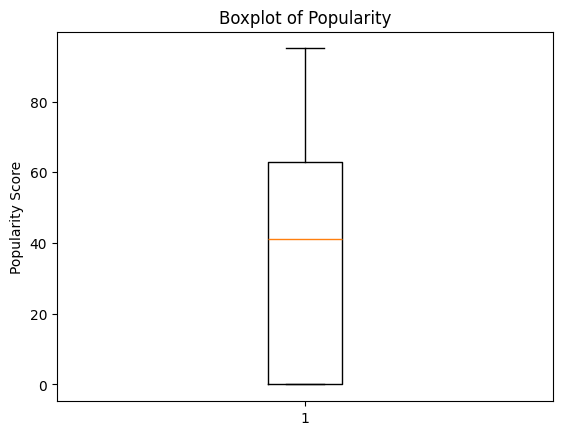

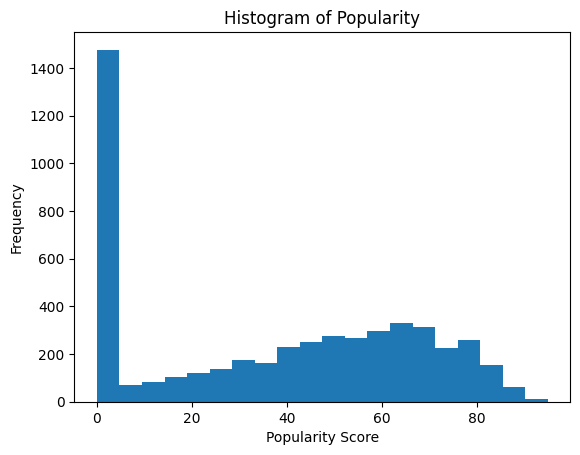

In [33]:
# Boxplot Popularity
plt.figure()
plt.boxplot(df['Popularity'].dropna())
plt.title('Boxplot of Popularity')
plt.ylabel('Popularity Score')
plt.show()

# Histogram Popularity
plt.figure()
plt.hist(df['Popularity'].dropna(), bins=20)
plt.title('Histogram of Popularity')
plt.xlabel('Popularity Score')
plt.ylabel('Frequency')
plt.show()

**Visualisasi boxplot menunjukkan bahwa nilai popularitas memiliki rentang distribusi yang lebar (0–95) dengan median berada di sekitar nilai 41, yang mengindikasikan dominasi lagu dengan tingkat popularitas menengah. Terlihat adanya konsentrasi data pada nilai rendah (0) yang cukup besar, menandakan banyak lagu dengan tingkat popularitas sangat rendah atau tidak aktif diputar.Histogram memperlihatkan distribusi yang tidak normal (skewed distribution), dengan kepadatan tinggi pada nilai popularitas rendah dan distribusi yang menyebar pada rentang menengah hingga tinggi. Pola ini menunjukkan bahwa dataset tidak didominasi oleh lagu viral/trending, melainkan lebih merepresentasikan katalog musik umum yang beragam dari sisi popularitas.**

**Secara konseptual, variabel Popularity tidak digunakan sebagai fitur utama dalam similarity modeling karena bersifat dinamis, trend-based, dan tidak merepresentasikan karakteristik audio intrinsik lagu, namun tetap dipertahankan sebagai informasi kontekstual untuk analisis tambahan dan interpretasi hasil rekomendasi.**

**Denceability**

In [34]:
df['Danceability'].describe()

count    4991.000000
mean        0.607737
std         0.146796
min         0.099400
25%         0.513000
50%         0.619000
75%         0.712000
max         0.988000
Name: Danceability, dtype: float64

In [35]:
df['Danceability'].value_counts()

Danceability
0.653    23
0.652    23
0.630    22
0.613    20
0.664    19
         ..
0.384     1
0.963     1
0.281     1
0.978     1
0.222     1
Name: count, Length: 719, dtype: int64

In [36]:
df['Danceability'].isna().sum()

np.int64(0)

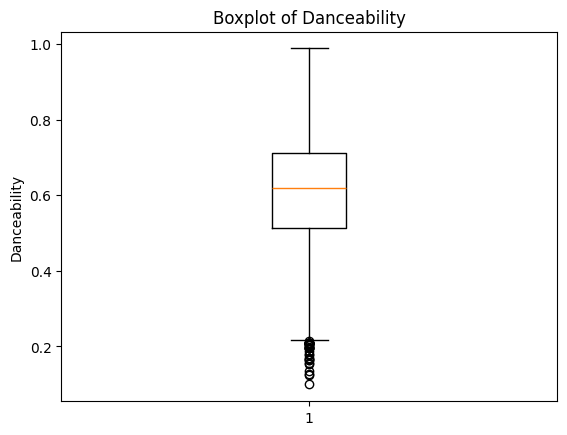

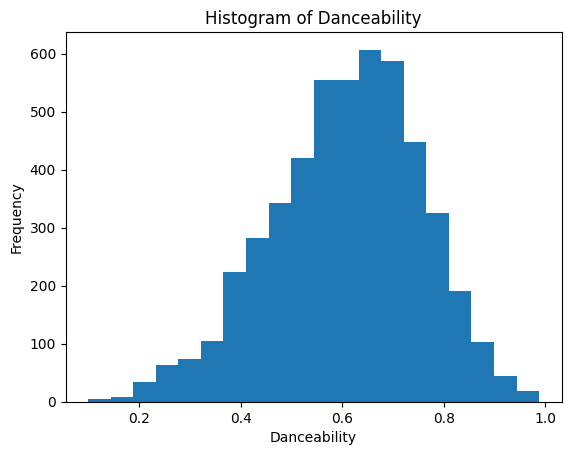

In [37]:
# Boxplot Danceability
plt.figure()
plt.boxplot(df['Danceability'].dropna())
plt.title('Boxplot of Danceability')
plt.ylabel('Danceability')
plt.show()

# Histogram Danceability
plt.figure()
plt.hist(df['Danceability'].dropna(), bins=20)
plt.title('Histogram of Danceability')
plt.xlabel('Danceability')
plt.ylabel('Frequency')
plt.show()


**Distribusi nilai Danceability menunjukkan konsentrasi data pada rentang menengah hingga tinggi (sekitar 0.5–0.8), dengan median berada di sekitar nilai 0.62, yang mengindikasikan bahwa mayoritas lagu dalam dataset memiliki karakter ritmis yang kuat dan cocok untuk musik upbeat atau dance-oriented. Boxplot memperlihatkan rentang nilai yang cukup lebar tanpa anomali ekstrem yang signifikan, menunjukkan distribusi yang relatif stabil. Histogram menunjukkan sebaran yang tidak ekstrem dan terpusat pada nilai menengah, sehingga variabel ini memiliki daya diskriminasi yang baik dalam membedakan karakteristik lagu. Oleh karena itu, Danceability merupakan fitur yang relevan dan informatif untuk digunakan sebagai komponen utama dalam similarity modeling pada sistem rekomendasi lagu berbasis konten.**

**Energy**

In [38]:
df['Energy'].describe()

count    4991.000000
mean        0.684064
std         0.190970
min         0.020500
25%         0.564000
50%         0.710000
75%         0.836000
max         0.994000
Name: Energy, dtype: float64

In [39]:
df['Energy'].value_counts()

Energy
0.836    20
0.887    20
0.874    20
0.740    19
0.660    17
         ..
0.144     1
0.185     1
0.335     1
0.122     1
0.506     1
Name: count, Length: 810, dtype: int64

In [40]:
df['Energy'].isna().sum()

np.int64(0)

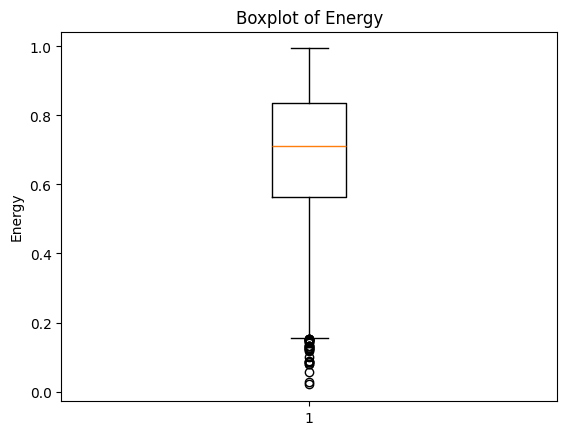

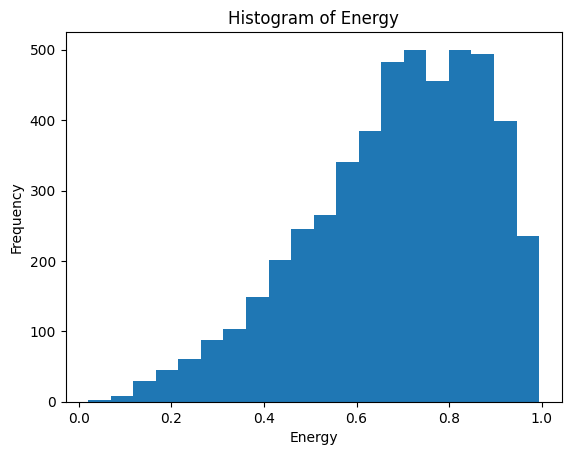

In [41]:
# Boxplot Energy
plt.figure()
plt.boxplot(df['Energy'].dropna())
plt.title('Boxplot of Energy')
plt.ylabel('Energy')
plt.show()

# Histogram Energy
plt.figure()
plt.hist(df['Energy'].dropna(), bins=20)
plt.title('Histogram of Energy')
plt.xlabel('Energy')
plt.ylabel('Frequency')
plt.show()


**Distribusi nilai Energy menunjukkan konsentrasi yang kuat pada rentang menengah hingga tinggi (sekitar 0.55–0.85), dengan median berada di sekitar nilai 0.71, yang mengindikasikan bahwa mayoritas lagu dalam dataset memiliki karakter musikal yang enerjik, cepat, dan intens. Boxplot memperlihatkan rentang nilai yang luas tanpa outlier ekstrem yang dominan, menunjukkan distribusi yang stabil dan representatif. Histogram menunjukkan sebaran yang terpusat pada nilai menengah–tinggi, sehingga variabel Energy memiliki daya diskriminasi yang kuat dalam membedakan karakteristik lagu. Oleh karena itu, fitur ini merupakan komponen penting dalam similarity modeling pada sistem rekomendasi lagu berbasis konten karena merepresentasikan intensitas dan aktivitas musikal secara langsung.**

**Key**

In [42]:
df['Key'].describe()

count    4991.000000
mean        5.191946
std         3.589902
min         0.000000
25%         2.000000
50%         5.000000
75%         8.000000
max        11.000000
Name: Key, dtype: float64

In [43]:
df['Key'].value_counts()

Key
0.0     649
7.0     551
2.0     546
9.0     528
5.0     445
1.0     442
11.0    388
4.0     386
10.0    307
6.0     302
8.0     302
3.0     145
Name: count, dtype: int64

In [44]:
df['Key'].isna().sum()

np.int64(0)

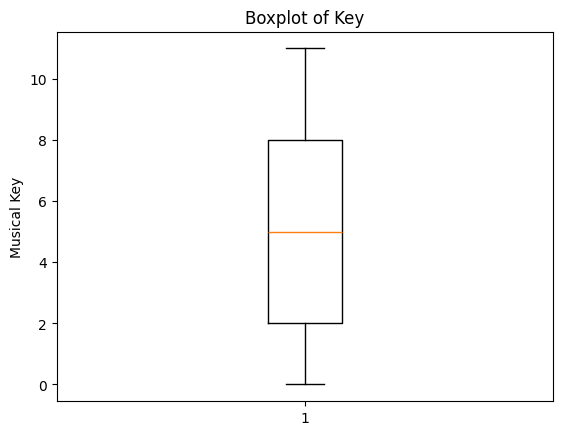

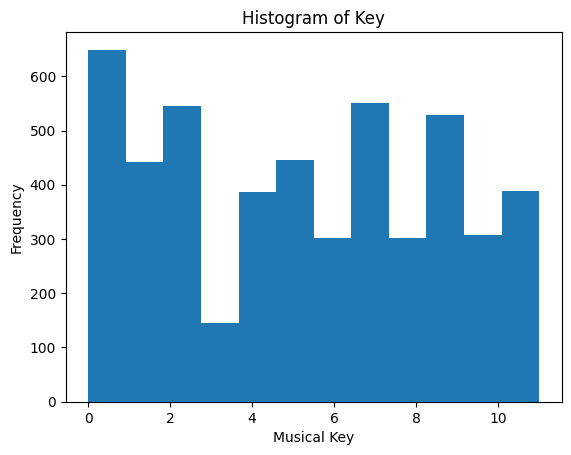

In [45]:
# Boxplot Key
plt.figure()
plt.boxplot(df['Key'].dropna())
plt.title('Boxplot of Key')
plt.ylabel('Musical Key')
plt.show()

# Histogram Key
plt.figure()
plt.hist(df['Key'].dropna(), bins=12)  # 12 nada dasar
plt.title('Histogram of Key')
plt.xlabel('Musical Key')
plt.ylabel('Frequency')
plt.show()


**Variabel Key memiliki nilai pada rentang 0–11 yang merepresentasikan 12 nada dasar dalam sistem musik kromatik, dengan distribusi yang relatif merata di seluruh kelas nada. Nilai median berada di sekitar 5, menunjukkan bahwa tidak ada dominasi ekstrem pada satu nada tertentu. Distribusi ini mencerminkan keberagaman tonalitas musik dalam dataset dan menunjukkan bahwa lagu-lagu tersebar secara seimbang pada berbagai tangga nada. Meskipun Key bukan fitur yang dominan secara emosional dibandingkan fitur seperti Energy atau Valence, variabel ini tetap relevan sebagai fitur pendukung dalam similarity modeling karena berkontribusi pada kemiripan struktural dan harmonik antar lagu dalam sistem rekomendasi berbasis konten.**

**Loudness**

In [46]:
df['Loudness'].describe()

count    4991.000000
mean       -7.286228
std         3.322893
min       -23.242000
25%        -9.079000
50%        -6.492000
75%        -4.903000
max         2.769000
Name: Loudness, dtype: float64

In [47]:
df['Loudness'].value_counts()

Loudness
-6.492     6
-4.057     6
-3.756     5
-6.654     5
-6.449     4
          ..
-6.623     1
-12.606    1
-9.392     1
-14.976    1
-6.977     1
Name: count, Length: 3881, dtype: int64

In [48]:
df['Loudness'].isna().sum()

np.int64(0)

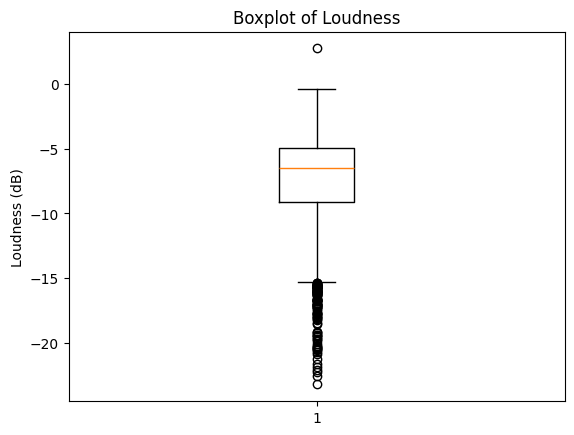

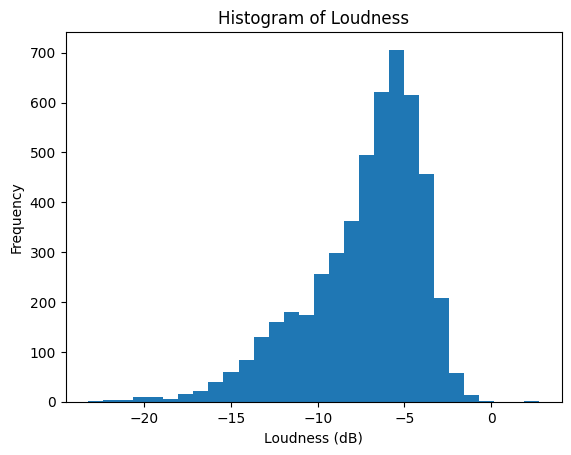

In [49]:
# Boxplot Loudness
plt.figure()
plt.boxplot(df['Loudness'].dropna())
plt.title('Boxplot of Loudness')
plt.ylabel('Loudness (dB)')
plt.show()

# Histogram Loudness
plt.figure()
plt.hist(df['Loudness'].dropna(), bins=30)
plt.title('Histogram of Loudness')
plt.xlabel('Loudness (dB)')
plt.ylabel('Frequency')
plt.show()


**Distribusi nilai Loudness menunjukkan konsentrasi kuat pada rentang −10 dB hingga −4 dB, dengan median sekitar −6.49 dB, yang merepresentasikan karakter audio yang relatif keras dan terkompresi sebagaimana standar produksi musik modern. Boxplot menunjukkan sebaran yang cukup lebar, mulai dari nilai sangat rendah (≈ −23 dB) hingga mendekati 0 dB (≈ +2.7 dB), yang mencerminkan variasi intensitas produksi antar lagu. Histogram memperlihatkan distribusi yang tidak simetris sempurna (skewed), dengan dominasi pada nilai loudness menengah-tinggi, mengindikasikan bahwa mayoritas lagu dalam dataset telah melalui proses mastering yang agresif. Variabel ini memiliki peran penting dalam membentuk persepsi energi dan intensitas lagu, sehingga sangat relevan sebagai fitur utama dalam sistem rekomendasi berbasis konten.**

**Mode**

In [50]:
df['Mode'].describe()

count    4991.000000
mean        0.702665
std         0.457131
min         0.000000
25%         0.000000
50%         1.000000
75%         1.000000
max         1.000000
Name: Mode, dtype: float64

In [51]:
df['Mode'].value_counts()

Mode
1.0    3507
0.0    1484
Name: count, dtype: int64

In [52]:
df['Mode'].isna().sum()

np.int64(0)

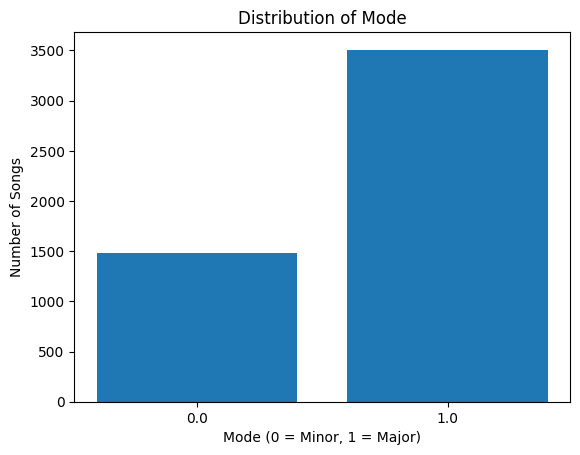

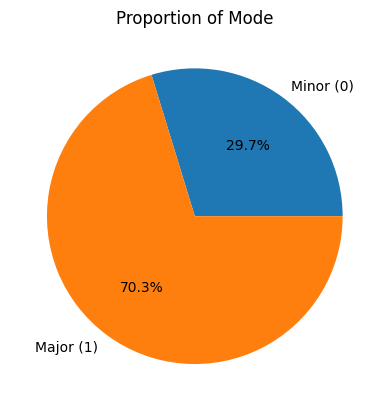

In [53]:
# Bar chart Mode
mode_counts = df['Mode'].value_counts().sort_index()

plt.figure()
plt.bar(mode_counts.index.astype(str), mode_counts.values)
plt.title('Distribution of Mode')
plt.xlabel('Mode (0 = Minor, 1 = Major)')
plt.ylabel('Number of Songs')
plt.show()

# Pie chart Mode
plt.figure()
plt.pie(mode_counts.values, labels=['Minor (0)', 'Major (1)'], autopct='%1.1f%%')
plt.title('Proportion of Mode')
plt.show()

**Distribusi variabel **Mode** menunjukkan dominasi yang jelas pada nilai **1 (Major scale)** dibandingkan **0 (Minor scale)**, dengan sekitar **70% lagu berada pada mode major**. Hal ini mengindikasikan bahwa mayoritas lagu dalam dataset memiliki karakter musikal yang **cerah, positif, dan uplifting**, dibandingkan nuansa emosional yang gelap atau sedih. Ketidakseimbangan distribusi ini menunjukkan adanya bias tonalitas dalam dataset, yang mencerminkan preferensi produksi dan konsumsi musik populer terhadap nuansa mayor. Dalam sistem rekomendasi berbasis konten, **Mode** berperan sebagai fitur emosional biner yang penting untuk membedakan mood lagu (happy vs sad), namun sebaiknya dikombinasikan dengan fitur lain seperti **Valence, Energy, dan Danceability** agar representasi emosi musik menjadi lebih kaya dan akurat.**

**Speechines**

In [54]:
df['Speechiness'].describe()

count    4991.00000
mean        0.06497
std         0.06017
min         0.02180
25%         0.03330
50%         0.04310
75%         0.06830
max         0.51900
Name: Speechiness, dtype: float64

In [55]:
df['Speechiness'].value_counts()

Speechiness
0.0295    29
0.0315    28
0.0298    28
0.0311    27
0.0321    26
          ..
0.0816     1
0.0230     1
0.2950     1
0.0621     1
0.0703     1
Name: count, Length: 948, dtype: int64

In [56]:
df['Speechiness'].isna().sum()

np.int64(0)

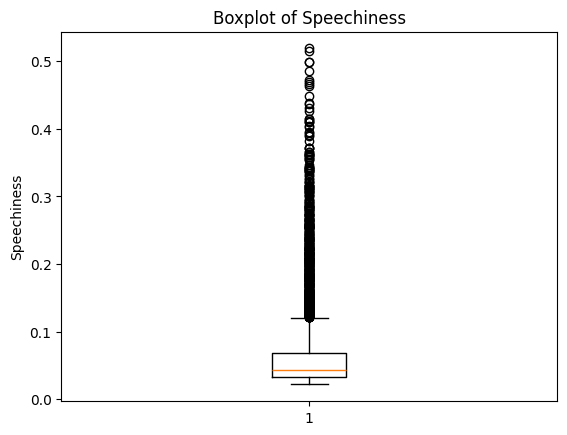

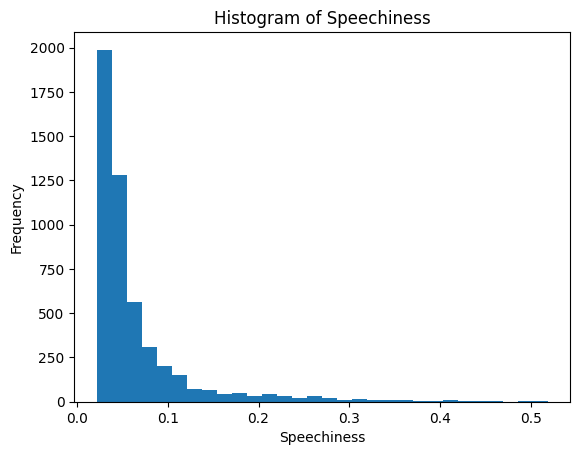

In [57]:
# Boxplot Speechiness
plt.figure()
plt.boxplot(df['Speechiness'].dropna())
plt.title('Boxplot of Speechiness')
plt.ylabel('Speechiness')
plt.show()

# Histogram Speechiness
plt.figure()
plt.hist(df['Speechiness'].dropna(), bins=30)
plt.title('Histogram of Speechiness')
plt.xlabel('Speechiness')
plt.ylabel('Frequency')
plt.show()

**Distribusi nilai **Speechiness** sangat terkonsentrasi pada nilai rendah (≈ 0.02–0.07) dengan median sekitar **0.043**, yang menunjukkan bahwa mayoritas lagu dalam dataset didominasi oleh **unsur musikal dan vokal bernada**, bukan percakapan atau spoken words. Boxplot memperlihatkan distribusi yang **right-skewed** (miring ke kanan), dengan sebagian kecil lagu memiliki nilai speechiness tinggi yang merepresentasikan genre seperti **rap, spoken word, atau talk-based content**. Histogram menegaskan bahwa hanya sebagian kecil observasi yang memiliki nilai tinggi, sehingga fitur ini bersifat **sparse** namun informatif. Dalam sistem rekomendasi berbasis konten, **Speechiness** berfungsi sebagai fitur spesialis untuk membedakan lagu berbasis percakapan vs musikal, dan sangat berguna dalam personalisasi rekomendasi genre seperti hip-hop, rap, dan spoken content.**

**Acousticnes**

In [58]:
df['Acousticness'].describe()

count    4841.000000
mean        0.208097
std         0.248354
min         0.000003
25%         0.018300
50%         0.098300
75%         0.312000
max         0.991000
Name: Acousticness, dtype: float64

In [59]:
df['Acousticness'].value_counts()

Acousticness
0.113000    17
0.110000    13
0.117000    12
0.127000    12
0.130000    12
            ..
0.000367     1
0.948000     1
0.278000     1
0.002590     1
0.005300     1
Name: count, Length: 2110, dtype: int64

In [60]:
df['Acousticness'].isna().sum()

np.int64(150)

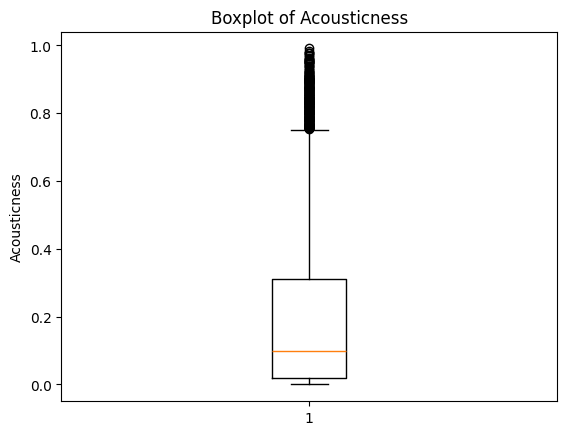

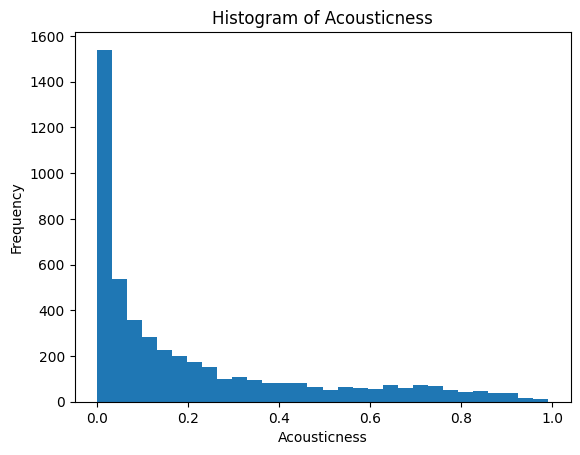

In [61]:
# Boxplot Acousticness
plt.figure()
plt.boxplot(df['Acousticness'].dropna())
plt.title('Boxplot of Acousticness')
plt.ylabel('Acousticness')
plt.show()

# Histogram Acousticness
plt.figure()
plt.hist(df['Acousticness'].dropna(), bins=30)
plt.title('Histogram of Acousticness')
plt.xlabel('Acousticness')
plt.ylabel('Frequency')
plt.show()

**Distribusi nilai **Acousticness** menunjukkan pola **right-skewed**, dengan mayoritas lagu berada pada nilai rendah (≈ 0–0.2), yang mengindikasikan dominasi musik berbasis **elektronik dan instrumen non-akustik** dalam dataset. Median yang jauh lebih kecil dibandingkan mean menunjukkan adanya sebagian kecil lagu dengan nilai acousticness sangat tinggi yang menarik distribusi ke kanan. Boxplot dan histogram memperlihatkan sebaran yang tidak simetris dengan ekor panjang di sisi kanan, merepresentasikan lagu-lagu akustik murni sebagai minoritas dalam dataset.**  

**Missing value pada variabel ini diatasi menggunakan **median imputation**, karena median lebih robust terhadap distribusi tidak simetris dan outlier dibandingkan mean. Dengan demikian, nilai imputasi tetap merepresentasikan karakteristik mayoritas data tanpa menggeser distribusi secara signifikan. Variabel **Acousticness** memiliki peran penting dalam sistem rekomendasi berbasis konten karena mampu membedakan karakter lagu akustik vs elektronik, sehingga sangat relevan untuk modeling similarity dan segmentasi preferensi pengguna.**

In [62]:
median_acoustic = df['Acousticness'].median()
df['Acousticness'] = df['Acousticness'].fillna(median_acoustic)

df['Acousticness'].isna().sum()

np.int64(0)

**Instrumentalness**

In [63]:
df['Instrumentalness'].describe()

count    4991.000000
mean        0.031152
std         0.128160
min         0.000000
25%         0.000000
50%         0.000005
75%         0.000601
max         0.985000
Name: Instrumentalness, dtype: float64

In [64]:
df['Instrumentalness'].value_counts()

Instrumentalness
0.000000    2015
0.000001       8
0.000002       8
0.000001       8
0.000022       7
            ... 
0.000848       1
0.383000       1
0.517000       1
0.000027       1
0.002220       1
Name: count, Length: 2010, dtype: int64

In [65]:
df['Instrumentalness'].isna().sum()

np.int64(0)

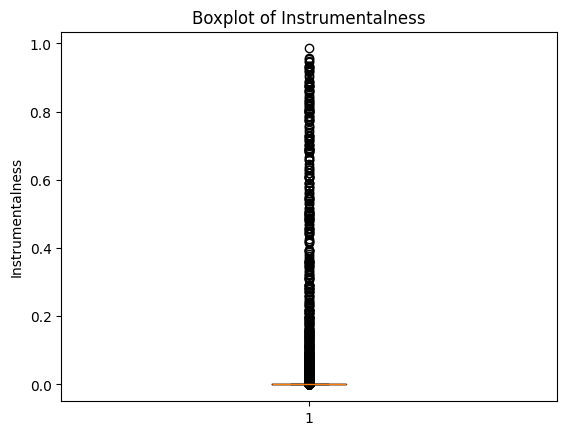

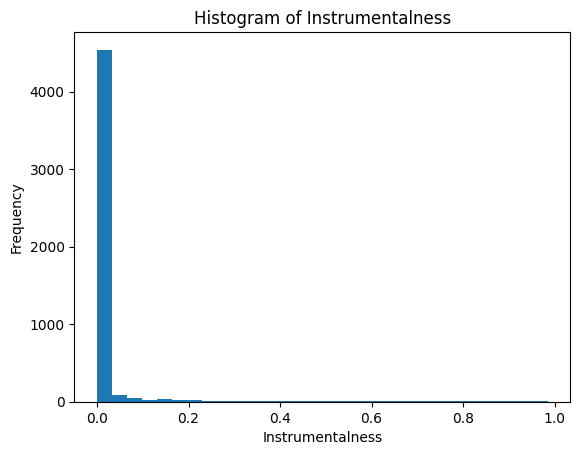

In [66]:
# Boxplot Instrumentalness
plt.figure()
plt.boxplot(df['Instrumentalness'].dropna())
plt.title('Boxplot of Instrumentalness')
plt.ylabel('Instrumentalness')
plt.show()

# Histogram Instrumentalness
plt.figure()
plt.hist(df['Instrumentalness'].dropna(), bins=30)
plt.title('Histogram of Instrumentalness')
plt.xlabel('Instrumentalness')
plt.ylabel('Frequency')
plt.show()

**Distribusi variabel **Instrumentalness** menunjukkan pola **right-skewed ekstrem**, dengan mayoritas nilai berada sangat dekat dengan **0**, yang mengindikasikan bahwa hampir seluruh lagu dalam dataset merupakan lagu **bervokal**, bukan instrumental. Median yang mendekati nol dan dominasi nilai nol memperlihatkan bahwa lagu instrumental murni merupakan **minoritas kecil** dalam dataset. Boxplot dan histogram menunjukkan ekor panjang di sisi kanan, yang merepresentasikan sejumlah kecil lagu dengan nilai instrumentalness tinggi sebagai outlier natural (musik instrumental murni).**

**Liveness**

In [67]:
df['Liveness'].describe()

count    4991.000000
mean        0.186368
std         0.150364
min         0.012000
25%         0.089200
50%         0.127000
75%         0.247500
max         0.989000
Name: Liveness, dtype: float64

In [68]:
df['Liveness'].value_counts()

Liveness
0.1050    48
0.1070    45
0.1080    44
0.1100    43
0.1040    43
          ..
0.7710     1
0.0506     1
0.9180     1
0.0905     1
0.0469     1
Name: count, Length: 1140, dtype: int64

In [69]:
df['Liveness'].isna().sum()

np.int64(0)

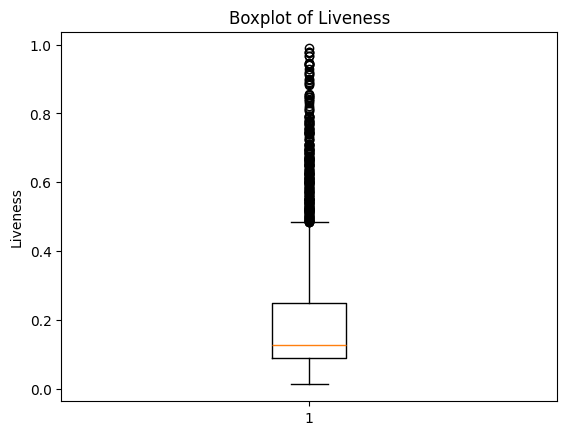

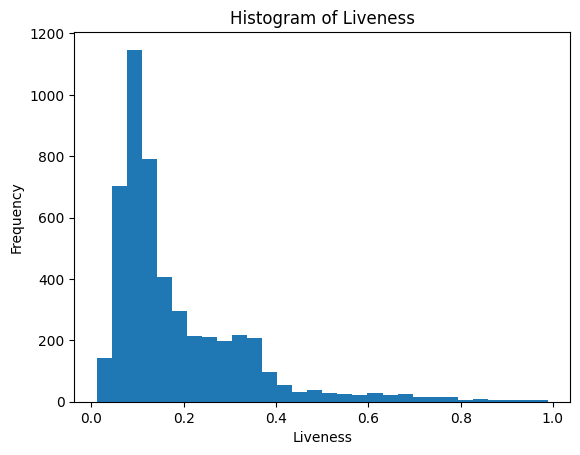

In [70]:
# Boxplot Liveness
plt.figure()
plt.boxplot(df['Liveness'].dropna())
plt.title('Boxplot of Liveness')
plt.ylabel('Liveness')
plt.show()

# Histogram Liveness
plt.figure()
plt.hist(df['Liveness'].dropna(), bins=30)
plt.title('Histogram of Liveness')
plt.xlabel('Liveness')
plt.ylabel('Frequency')
plt.show()

**Distribusi variabel **Liveness** menunjukkan konsentrasi kuat pada nilai **rendah hingga menengah** (≈ 0.05–0.25), dengan median sekitar **0.127**, yang mengindikasikan bahwa mayoritas lagu dalam dataset merupakan hasil **rekaman studio**, bukan pertunjukan langsung. Boxplot dan histogram memperlihatkan distribusi yang sedikit **right-skewed**, dengan sebagian kecil lagu memiliki nilai liveness tinggi yang merepresentasikan **live recording, konser, atau performa langsung**.**

**Valance**

In [71]:
df['Valence'].describe()

count    4991.000000
mean        0.587958
std         0.239424
min         0.033400
25%         0.400000
50%         0.601000
75%         0.787000
max         0.995000
Name: Valence, dtype: float64

In [72]:
df['Valence'].value_counts()

Valence
0.9610    33
0.9630    26
0.9650    19
0.9620    19
0.9640    18
          ..
0.9680     1
0.0694     1
0.9210     1
0.0592     1
0.1670     1
Name: count, Length: 928, dtype: int64

In [73]:
df['Valence'].isna().sum()

np.int64(0)

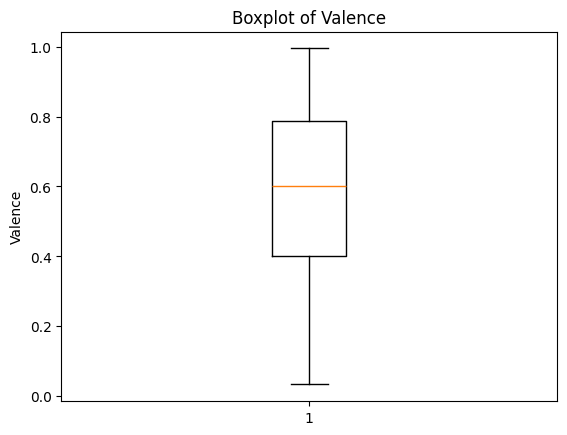

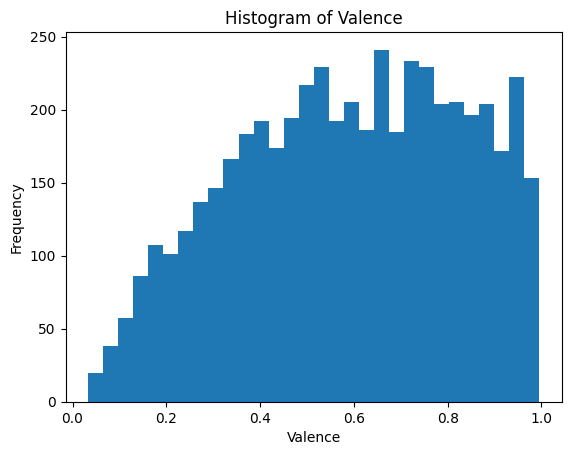

In [74]:
# Boxplot Valence
plt.figure()
plt.boxplot(df['Valence'].dropna())
plt.title('Boxplot of Valence')
plt.ylabel('Valence')
plt.show()

# Histogram Valence
plt.figure()
plt.hist(df['Valence'].dropna(), bins=30)
plt.title('Histogram of Valence')
plt.xlabel('Valence')
plt.ylabel('Frequency')
plt.show()

**Distribusi nilai **Valence** menunjukkan konsentrasi pada rentang **menengah hingga tinggi** (≈ 0.4–0.8), dengan median sekitar **0.60**, yang mengindikasikan bahwa mayoritas lagu dalam dataset memiliki karakter emosional yang **positif, cerah, dan uplifting**. Boxplot dan histogram memperlihatkan sebaran yang relatif seimbang tanpa outlier ekstrem yang tidak wajar, sehingga distribusi dapat dianggap stabil dan representatif.**

**Tempo**

In [75]:
df['Tempo'].describe()

count    4741.000000
mean      121.188521
std        26.338393
min        59.406000
25%       102.039000
50%       120.336000
75%       134.196000
max       217.913000
Name: Tempo, dtype: float64

In [76]:
df['Tempo'].value_counts()

Tempo
119.999    4
119.961    4
119.992    4
130.014    4
127.966    4
          ..
125.495    1
139.428    1
84.126     1
133.019    1
118.351    1
Name: count, Length: 4391, dtype: int64

In [77]:
df['Tempo'].isna().sum()

np.int64(250)

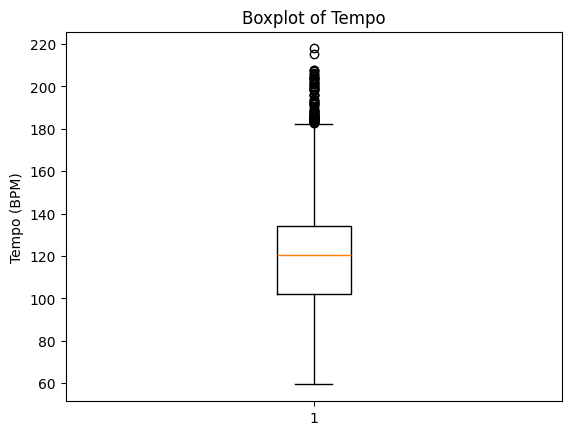

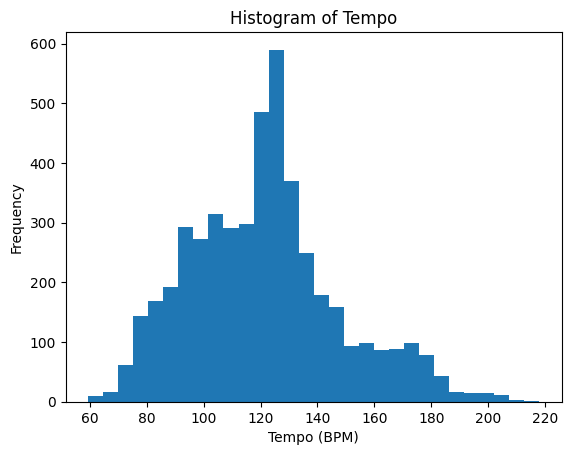

In [78]:
# Boxplot Tempo
plt.figure()
plt.boxplot(df['Tempo'].dropna())
plt.title('Boxplot of Tempo')
plt.ylabel('Tempo (BPM)')
plt.show()

# Histogram Tempo
plt.figure()
plt.hist(df['Tempo'].dropna(), bins=30)
plt.title('Histogram of Tempo')
plt.xlabel('Tempo (BPM)')
plt.ylabel('Frequency')
plt.show()

In [79]:
median_tempo = df['Tempo'].median()
df['Tempo'] = df['Tempo'].fillna(median_tempo)

**Distribusi nilai **Tempo** menunjukkan pola yang relatif **simetris** dengan konsentrasi utama pada rentang **100–140 BPM**, serta median sekitar **120 BPM**, yang merupakan tempo khas musik populer modern seperti pop, rock, hip-hop, dan dance. Boxplot dan histogram memperlihatkan sebaran yang stabil dengan variasi alami dari lagu lambat hingga cepat, tanpa anomali ekstrem yang tidak wajar.**

**Terdapat **250 missing value** pada variabel Tempo yang ditangani menggunakan **median imputation**, karena median lebih robust terhadap nilai ekstrem dan tetap merepresentasikan pusat distribusi data secara akurat. Dengan imputasi ini, struktur distribusi tempo tetap terjaga dan tidak mengalami distorsi statistik.**  

**Dalam sistem rekomendasi berbasis konten, **Tempo** merupakan fitur penting yang merepresentasikan **ritme dan kecepatan lagu**, sehingga sangat relevan untuk similarity modeling dan personalisasi rekomendasi berbasis preferensi tempo pengguna (slow vs fast music preference).**

**Time Signature**

In [80]:
df['Time Signature'].describe()

count    4991.000000
mean        3.959728
std         0.238946
min         1.000000
25%         4.000000
50%         4.000000
75%         4.000000
max         5.000000
Name: Time Signature, dtype: float64

In [81]:
df['Time Signature'].value_counts()

Time Signature
4.0    4754
3.0     205
5.0      25
1.0       7
Name: count, dtype: int64

In [82]:
df['Time Signature'].isna().sum()

np.int64(0)

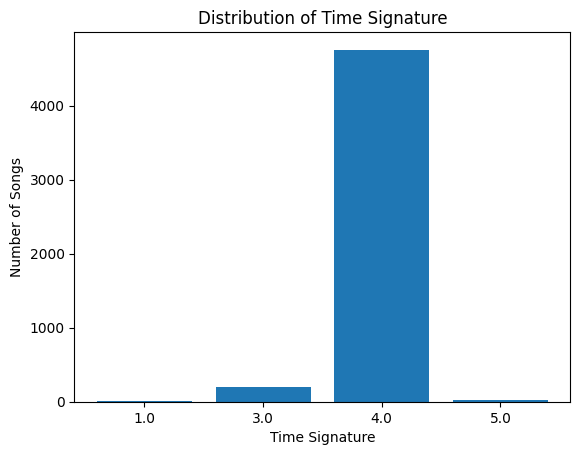

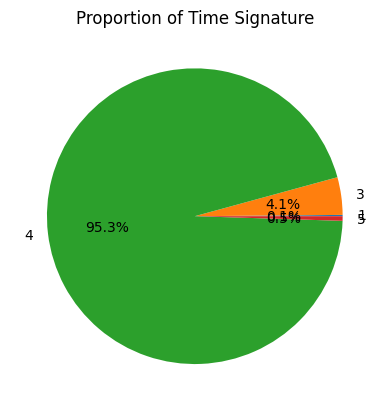

In [83]:
# Bar chart Time Signature
ts_counts = df['Time Signature'].value_counts().sort_index()

plt.figure()
plt.bar(ts_counts.index.astype(str), ts_counts.values)
plt.title('Distribution of Time Signature')
plt.xlabel('Time Signature')
plt.ylabel('Number of Songs')
plt.show()

# Pie chart Time Signature
plt.figure()
plt.pie(ts_counts.values, labels=ts_counts.index.astype(int), autopct='%1.1f%%')
plt.title('Proportion of Time Signature')
plt.show()

**Distribusi variabel **Time Signature** menunjukkan dominasi yang sangat kuat pada nilai **4/4**, yang mencakup sekitar **95% dari seluruh lagu** dalam dataset. Hal ini mencerminkan standar global musik populer modern yang secara dominan menggunakan pola ritme **empat ketukan per bar**. Nilai lain seperti **3/4, 5/4, dan 1/4** hanya muncul dalam proporsi yang sangat kecil, sehingga variasi ritmik dalam dataset tergolong rendah.**

In [84]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4991 entries, 0 to 4990
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Track URI           4991 non-null   object 
 1   Track Name          4991 non-null   object 
 2   Artist Name(s)      4991 non-null   object 
 3   Album Name          4991 non-null   object 
 4   Album Release Date  4991 non-null   object 
 5   Popularity          4991 non-null   int64  
 6   Artist Genres       4696 non-null   object 
 7   Danceability        4991 non-null   float64
 8   Energy              4991 non-null   float64
 9   Key                 4991 non-null   float64
 10  Loudness            4991 non-null   float64
 11  Mode                4991 non-null   float64
 12  Speechiness         4991 non-null   float64
 13  Acousticness        4991 non-null   float64
 14  Instrumentalness    4991 non-null   float64
 15  Liveness            4991 non-null   float64
 16  Valenc

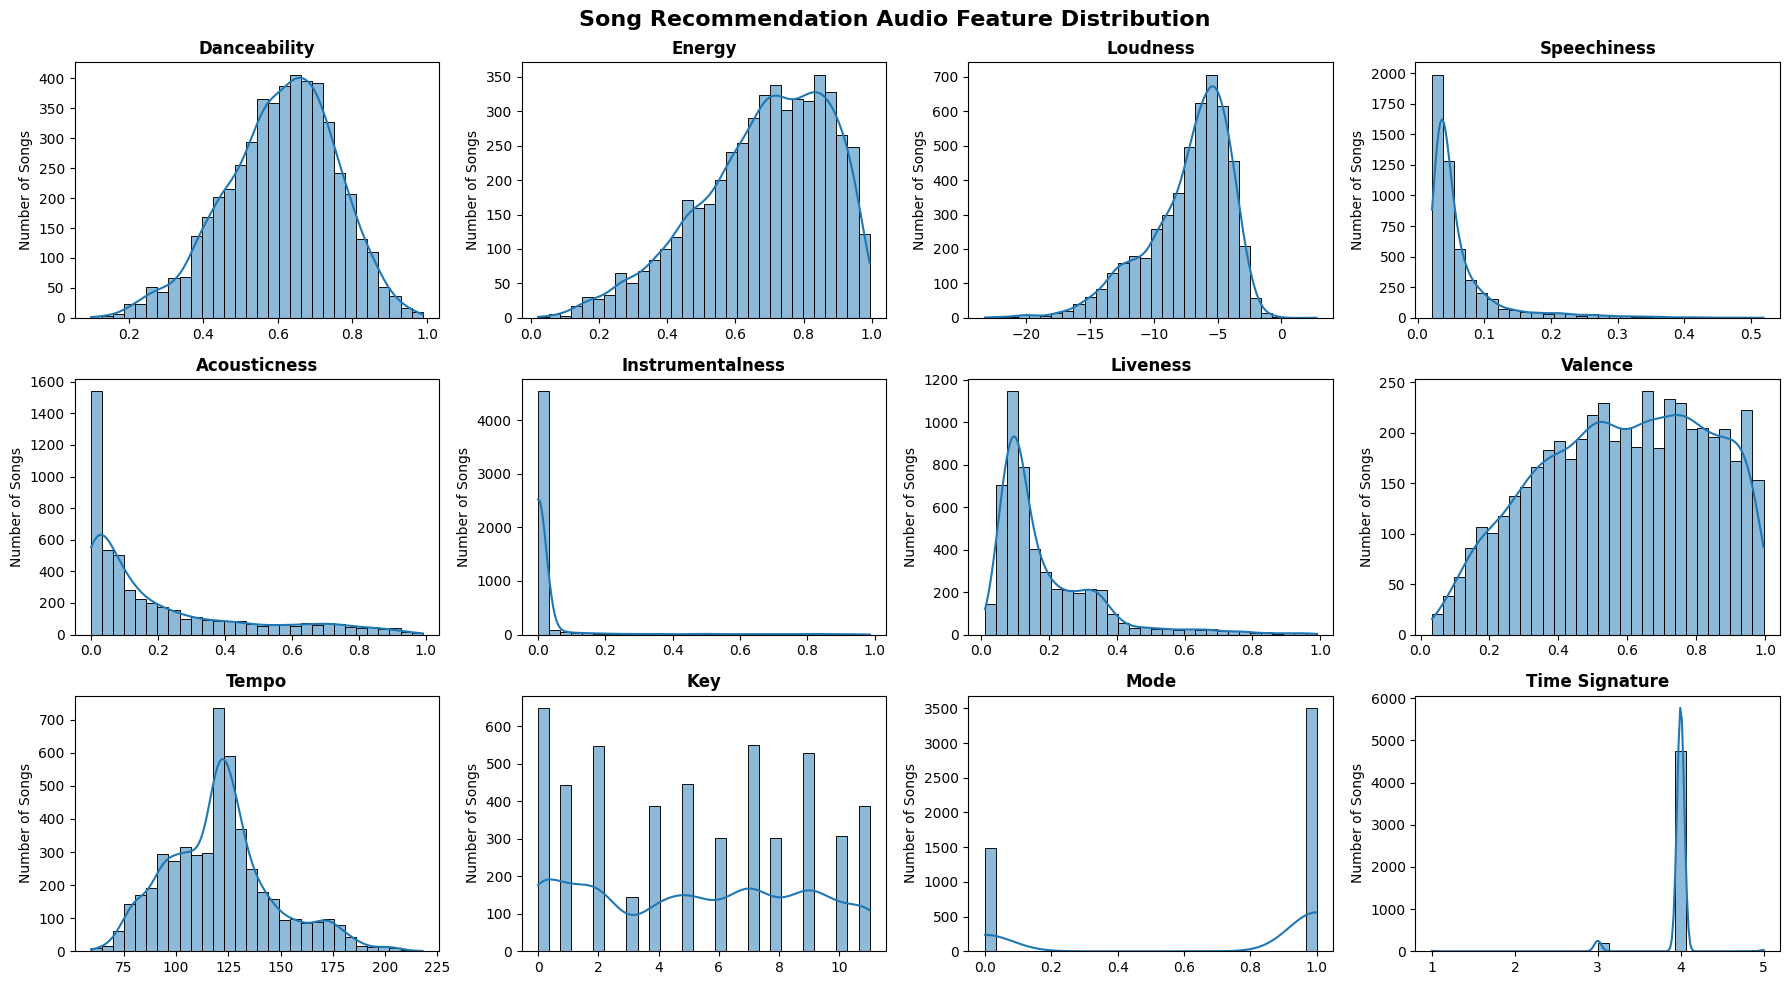

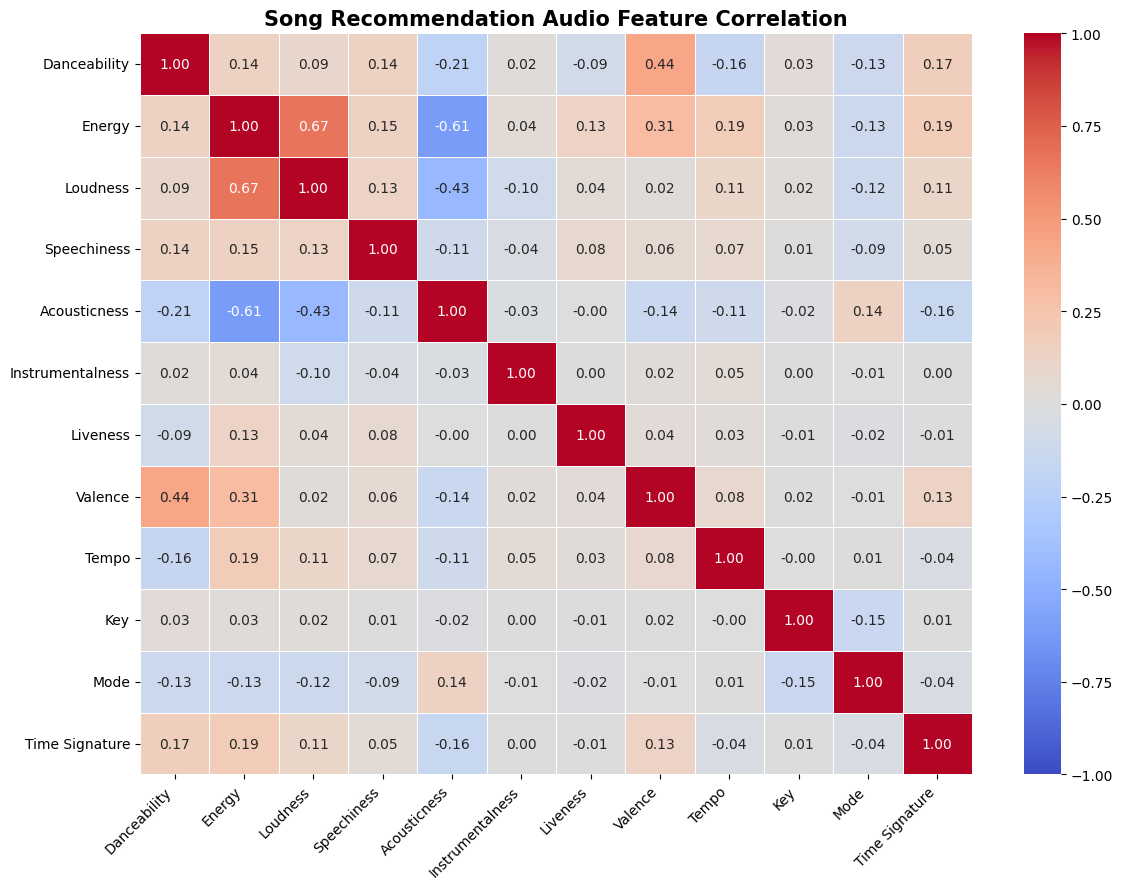

In [86]:

# ==========================================
# AUDIO FEATURE DISTRIBUTION
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

audio_features = [
    'Danceability',
    'Energy',
    'Loudness',
    'Speechiness',
    'Acousticness',
    'Instrumentalness',
    'Liveness',
    'Valence',
    'Tempo',
    'Key',
    'Mode',
    'Time Signature'
]

fig, axes = plt.subplots(3, 4, figsize=(18, 10))
axes = axes.flatten()

for i, feature in enumerate(audio_features):
    sns.histplot(
        data=df,
        x=feature,
        bins=30,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(feature, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Number of Songs')

fig.suptitle(
    'Song Recommendation Audio Feature Distribution',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


# ==========================================
# AUDIO FEATURE CORRELATION
# ==========================================

correlation_matrix = df[audio_features].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title(
    'Song Recommendation Audio Feature Correlation',
    fontsize=15,
    fontweight='bold'
)

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


**Feature Selection**

In [87]:
audio_features = [
    'Danceability',
    'Energy',
    'Loudness',
    'Speechiness',
    'Acousticness',
    'Instrumentalness',
    'Liveness',
    'Valence',
    'Tempo',
    'Key',
    'Mode',
    'Time Signature'
]

# features matrix
X = df[audio_features].copy()

**Tahap feature selection dilakukan dengan memilih variabel-variabel yang secara langsung merepresentasikan karakteristik audio intrinsik lagu sebagai dasar pembentukan feature space pemodelan. Variabel yang dipilih mencakup aspek ritme, energi, tonalitas, struktur musikal, dan emosi, yaitu: Danceability, Energy, Loudness, Speechiness, Acousticness, Instrumentalness, Liveness, Valence, Tempo, Key, Mode, dan Time Signature.**

**Pemilihan fitur ini bertujuan untuk memastikan bahwa proses pengukuran kemiripan antar lagu didasarkan pada atribut musikal objektif, bukan pada metadata atau informasi identitas lagu. Variabel metadata seperti judul lagu, artis, album, popularitas, dan genre tetap dipertahankan dalam dataset utama untuk keperluan sistem, namun tidak digunakan dalam proses pemodelan similarity.**

**Scaling**

In [88]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# scaling feature space
X_scaled = scaler.fit_transform(X)

# convert ke DataFrame
X_scaled = pd.DataFrame(X_scaled, columns=audio_features)

X_scaled.head()

,Danceability,Energy,Loudness,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Key,Mode,Time Signature
0,0.431000,0.879474,0.520450,-0.373475,-0.759919,-0.242320,-0.680204,0.622566,0.151829,-0.889235,-1.537273,0.168559
1,-0.127656,-1.231021,-0.561847,0.665355,1.639731,-0.242923,-0.574450,-1.791806,-0.108882,0.503701,0.650503,-4.016905
2,-1.646927,-2.336019,-1.976419,-0.446608,1.798729,-0.243015,-0.656925,-1.908765,-2.056386,-1.167822,0.650503,0.168559
3,0.478690,-0.131259,-1.627893,-0.421676,-0.738719,-0.228110,-0.744720,1.299259,-0.296235,1.618049,-1.537273,0.168559
4,0.880650,0.895185,-0.912782,-0.006145,-0.815569,-0.242963,-0.155425,-0.020709,-0.199578,1.618049,-1.537273,0.168559


In [89]:
X_scaled.describe()

,Danceability,Energy,Loudness,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Key,Mode,Time Signature
count,4.991000e+03,4.991000e+03,4.991000e+03,4.991000e+03,4.991000e+03,4.991000e+03,4.991000e+03,4.991000e+03,4.991000e+03,4.991000e+03,4.991000e+03,4.991000e+03
mean,-3.288627e-16,-8.541888e-18,-1.267047e-16,5.979322e-17,-1.323993e-16,-9.253712e-18,-8.257159e-17,3.043048e-16,3.744194e-16,6.833511e-17,-7.972429e-17,5.466808e-16
std,1.000100e+00,1.000100e+00,1.000100e+00,1.000100e+00,1.000100e+00,1.000100e+00,1.000100e+00,1.000100e+00,1.000100e+00,1.000100e+00,1.000100e+00,1.000100e+00
min,-3.463240e+00,-3.475058e+00,-4.802252e+00,-7.175349e-01,-8.349227e-01,-2.430931e-01,-1.159754e+00,-2.316451e+00,-2.405300e+00,-1.446409e+00,-1.537273e+00,-1.238783e+01
25%,-6.454342e-01,-6.287702e-01,-5.395754e-01,-5.263904e-01,-7.542116e-01,-2.430931e-01,-6.462828e-01,-7.851214e-01,-6.948789e-01,-8.892346e-01,-1.537273e+00,1.685590e-01
50%,7.673065e-02,1.358258e-01,2.390410e-01,-3.635019e-01,-4.341767e-01,-2.430521e-01,-3.948679e-01,5.447857e-02,-3.154942e-02,-5.347353e-02,6.505026e-01,1.685590e-01
75%,7.103281e-01,7.956827e-01,7.172866e-01,5.535405e-02,4.003601e-01,-2.384032e-01,4.066000e-01,8.314218e-01,4.631670e-01,7.822876e-01,6.505026e-01,1.685590e-01
max,2.590682e+00,1.623122e+00,3.026349e+00,7.546560e+00,3.205252e+00,7.443396e+00,5.338455e+00,1.700262e+00,3.769919e+00,1.618049e+00,6.505026e-01,4.354023e+00


**Feature scaling dilakukan untuk menyamakan skala antar variabel audio sehingga setiap fitur memiliki kontribusi yang seimbang dalam perhitungan jarak dan similarity. Proses ini penting karena fitur audio memiliki rentang nilai yang berbeda-beda, seperti tempo dalam BPM, loudness dalam desibel, dan fitur lain dalam skala 0–1.**  

**Pada tahap ini digunakan metode **StandardScaler**, yang mentransformasikan setiap fitur menjadi distribusi dengan mean 0 dan standar deviasi 1. Metode ini menjaga struktur distribusi data sekaligus mencegah dominasi fitur tertentu dalam perhitungan similarity.**

**Hasil scaling membentuk sebuah **feature matrix terstandarisasi (X_scaled)** yang siap digunakan sebagai input utama dalam proses perhitungan similarity pada sistem rekomendasi lagu berbasis konten.**

**Recommender System**

In [90]:
from sklearn.metrics.pairwise import cosine_similarity

# hitung similarity matrix
similarity_matrix = cosine_similarity(X_scaled)

# mapping index
df = df.reset_index(drop=True)

def recommend_song(input_text, top_n=5):
    input_text = input_text.lower()
    
    # cari lagu berdasarkan text (judul / artist)
    mask = (
        df['Track Name'].str.lower().str.contains(input_text, na=False) |
        df['Artist Name(s)'].str.lower().str.contains(input_text, na=False)
    )
    
    if not mask.any():
        return "❌ Lagu / artis tidak ditemukan dalam dataset."
    
    # ambil index lagu pertama yang cocok
    idx = df[mask].index[0]
    
    # ambil similarity score
    sim_scores = list(enumerate(similarity_matrix[idx]))
    
    # urutkan berdasarkan similarity
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    
    # ambil top-N (skip dirinya sendiri)
    sim_scores = sim_scores[1:top_n+1]
    
    # ambil index
    song_indices = [i[0] for i in sim_scores]
    
    # return rekomendasi
    recommendations = df.loc[song_indices, [
        'Track Name',
        'Artist Name(s)',
        'Album Name',
        'Popularity'
    ]]
    
    return recommendations.reset_index(drop=True)


**Sistem rekomendasi yang dibangun menggunakan pendekatan content-based filtering, di mana rekomendasi lagu dihasilkan berdasarkan kemiripan karakteristik audio (audio features) antar lagu, bukan berdasarkan perilaku pengguna lain. Fitur-fitur seperti danceability, energy, loudness, speechiness, acousticness, instrumentalness, liveness, valence, tempo, key, mode, dan time signature digunakan sebagai representasi vektor numerik dari setiap lagu.**

**Testing**

In [91]:
recommend_song("love")

,Track Name,Artist Name(s),Album Name,Popularity
0,Love Don't Cost a Thing,Jennifer Lopez,J.Lo,0
1,Hit 'Em Up Style (Oops!),Blu Cantrell,Bittersweet,54
2,"Mama Do (Uh Oh, Uh Oh)",Pixie Lott,Turn It Up,0
3,Hit 'Em Up Style (Oops!),Blu Cantrell,So Blu,72
4,Down With The Trumpets,Rizzle Kicks,Stereo Typical,0


In [92]:
recommend_song("taylor swift")

,Track Name,Artist Name(s),Album Name,Popularity
0,Free,BROODS,Conscious,39
1,Miracles (Someone Special),"Coldplay, Big Sean",Kaleidoscope EP,65
2,Never Be Amazing,David Franj,"Wrong Place, Wrong Time",7
3,Nothing's Gonna Stop Us Now,Starship,No Protection,82
4,Kosciusko - Remastered Version,Midnight Oil,Essential Oils,25


In [93]:
recommend_song("dance")

,Track Name,Artist Name(s),Album Name,Popularity
0,Stolen Dance,Milky Chance,Sadnecessary,38
1,Break My Stride,Matthew Wilder,I Don't Speak The Language,76
2,Grease,Frankie Valli,The Very Best of Frankie Valli & The 4 Seasons,56
3,Break My Stride,Matthew Wilder,'80s Pop Hits,61
4,Stand by Me,Otis Redding,Pain in My Heart,72


**Hasil rekomendasi menunjukkan bahwa sistem mampu menghasilkan lagu-lagu yang memiliki kemiripan karakteristik audio dengan input yang diberikan. Untuk input berbasis judul atau artis, rekomendasi yang dihasilkan cenderung memiliki kesamaan pada aspek mood, energi, tempo, dan karakteristik musikal lainnya.**

**Untuk input bertema emosional seperti "love", sistem merekomendasikan lagu-lagu dengan nilai **valence dan energy yang sebanding**, menunjukkan konsistensi dalam pengenalan pola emosi musik. Pada input berbasis artis seperti "Taylor Swift", lagu-lagu rekomendasi menunjukkan kesamaan gaya musikal dan struktur audio. Sedangkan pada input bertema aktivitas seperti "dance", sistem menghasilkan lagu-lagu dengan **danceability dan energy tinggi**, yang sesuai secara semantik dengan konteks input.**

**Hal ini membuktikan bahwa sistem rekomendasi berbasis konten yang dibangun mampu melakukan **similarity matching secara musikal**, bukan hanya berbasis metadata teks, sehingga rekomendasi yang dihasilkan bersifat relevan dan bermakna secara audio.**

***Thank You***